## Sección 7: Data Visualization (Matplotlib & Seaborn) - La Guía Total
Regla de oro: Un gráfico debe ser auto-contenido (título, ejes etiquetados, leyenda si aplica) y honesto (escalas no engañosas).

### 7.1 Configuración Inicial y Conceptos Fundamentales

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

In [2]:
# 1. Estilos globales (Matplotlib y Seaborn)
plt.style.use('ggplot')  # Estilos: 'default', 'seaborn-v0_8', 'ggplot', 'fivethirtyeight'
sns.set_theme(style='whitegrid')  # Estilo Seaborn: 'darkgrid', 'whitegrid', 'dark', 'white', 'ticks'

# 2. Tamaño global de fuentes (para no estar ajustando en cada gráfico)
plt.rcParams['font.size'] = 12
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['legend.fontsize'] = 10

# 3. La Arquitectura: Figure (lienzo) vs Axes (subgráfico)
# Forma 1 (Estilo Pyplot - Rápido): plt.plot() -> crea figura y ejes implícitos.
# Forma 2 (Estilo Orientado a Objetos - RECOMENDADO): fig, ax = plt.subplots()
# Siempre usa la forma 2 para tener control total.

print("--- CONCEPTOS ---")
print("Figure = El lienzo completo (ventana)")
print("Axes = El área donde se dibuja el gráfico (puede haber varios dentro de una Figure)")

--- CONCEPTOS ---
Figure = El lienzo completo (ventana)
Axes = El área donde se dibuja el gráfico (puede haber varios dentro de una Figure)


## 7.2 Tipos de Gráficos Fundamentales (Matplotlib Puro)
A) Gráfico de Líneas (plot) - Para tendencias y series temporales

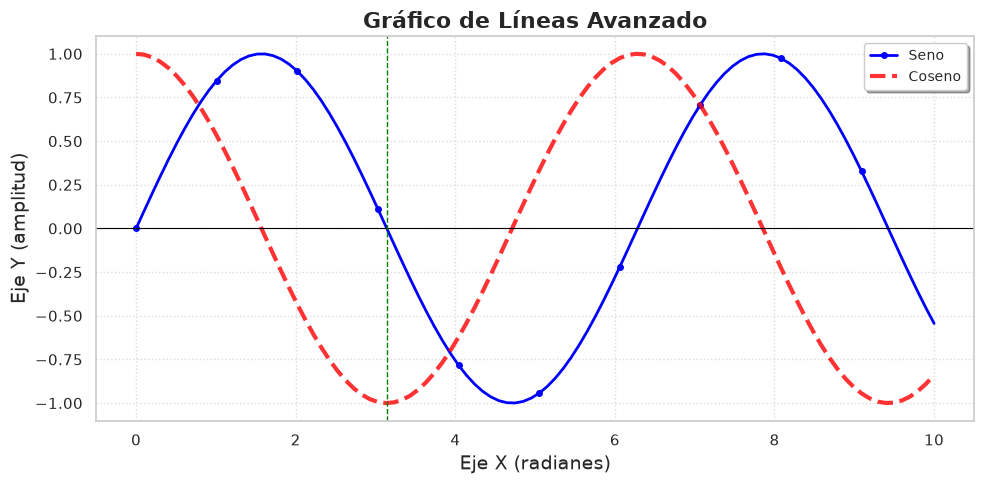

In [3]:
# Datos de ejemplo
x = np.linspace(0, 10, 100)
y1 = np.sin(x)
y2 = np.cos(x)

fig, ax = plt.subplots(figsize=(10, 5))

# Graficar líneas
ax.plot(x, y1, label='Seno', color='blue', linestyle='-', linewidth=2, marker='o', markersize=4, markevery=10)
ax.plot(x, y2, label='Coseno', color='red', linestyle='--', linewidth=3, alpha=0.8) # alpha = transparencia

# Personalización
ax.set_title('Gráfico de Líneas Avanzado', fontsize=16, fontweight='bold')
ax.set_xlabel('Eje X (radianes)')
ax.set_ylabel('Eje Y (amplitud)')
ax.legend(loc='upper right', frameon=True, shadow=True)
ax.grid(True, linestyle=':', alpha=0.7)  # Cuadrícula punteada

# Añadir una línea horizontal y vertical de referencia
ax.axhline(y=0, color='black', linestyle='-', linewidth=0.8)
ax.axvline(x=np.pi, color='green', linestyle='--', linewidth=1, label='π')

plt.tight_layout()  # Ajusta márgenes para que no se corten etiquetas
plt.show()

### B) Gráfico de Dispersión (scatter) - Para relaciones entre 2 numéricas


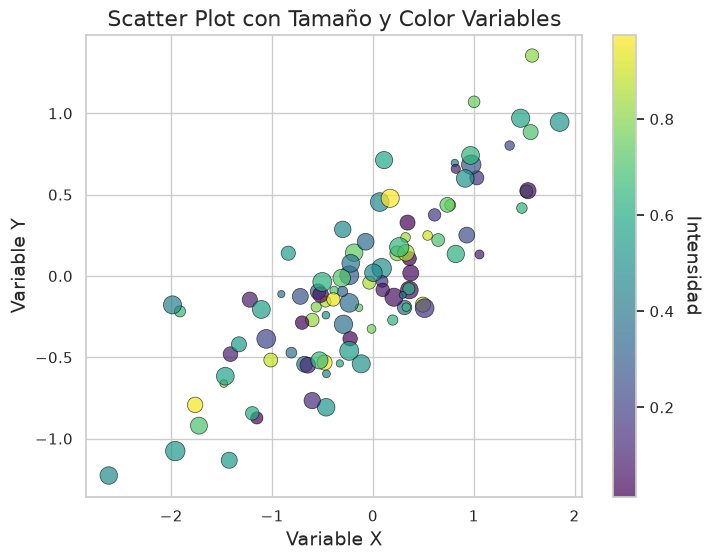

In [4]:
# Datos
np.random.seed(42)
x = np.random.randn(100)
y = x * 0.5 + np.random.randn(100) * 0.3
colores = np.random.rand(100)  # Para mapear a colores
tamaños = np.random.randint(20, 200, 100)  # Tamaños variables

fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(x, y, c=colores, s=tamaños, cmap='viridis', alpha=0.7, edgecolors='black', linewidth=0.5)

# Barra de color
cbar = plt.colorbar(sc)
cbar.set_label('Intensidad', rotation=270, labelpad=20)

ax.set_title('Scatter Plot con Tamaño y Color Variables')
ax.set_xlabel('Variable X')
ax.set_ylabel('Variable Y')

plt.show()

### C) Gráfico de Barras (bar / barh) - Para comparar categorías


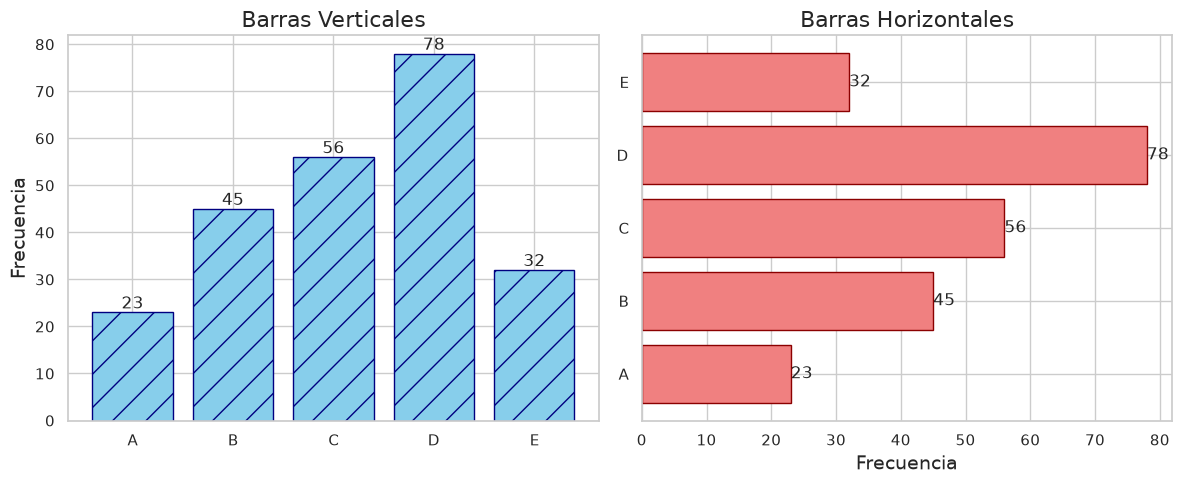

In [5]:
categorias = ['A', 'B', 'C', 'D', 'E']
valores = [23, 45, 56, 78, 32]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Barras verticales
ax1.bar(categorias, valores, color='skyblue', edgecolor='navy', hatch='/')  # hatch = patrón de relleno
ax1.set_title('Barras Verticales')
ax1.set_ylabel('Frecuencia')
ax1.bar_label(ax1.containers[0], fmt='%.0f')  # Añadir etiquetas ENCIMA de las barras (NUEVO y útil)

# Barras horizontales (mejor si las etiquetas son largas)
ax2.barh(categorias, valores, color='lightcoral', edgecolor='darkred')
ax2.set_title('Barras Horizontales')
ax2.set_xlabel('Frecuencia')
ax2.bar_label(ax2.containers[0], fmt='%.0f')  # Etiquetas a la derecha

plt.tight_layout()
plt.show()

### D) Histogramas (hist) - Distribución de 1 numérica


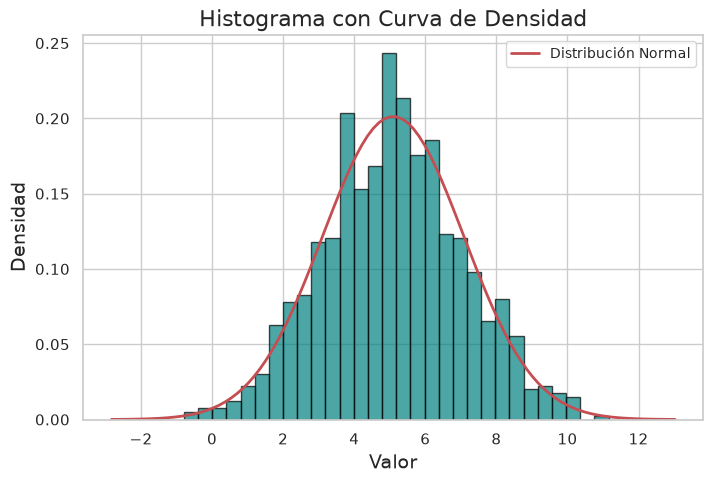

In [6]:
datos = np.random.randn(1000) * 2 + 5  # Media 5, desviación 2

fig, ax = plt.subplots(figsize=(8, 5))
# bins = número de barras, density=True para normalizar (área = 1)
n, bins, patches = ax.hist(datos, bins=30, density=True, alpha=0.7, color='teal', edgecolor='black')

# Añadir curva de densidad (KDE) manual con matplotlib
from scipy.stats import norm
mu, std = np.mean(datos), np.std(datos)
x_curve = np.linspace(mu - 4*std, mu + 4*std, 100)
y_curve = norm.pdf(x_curve, mu, std)
ax.plot(x_curve, y_curve, 'r-', linewidth=2, label='Distribución Normal')

ax.set_title('Histograma con Curva de Densidad')
ax.set_xlabel('Valor')
ax.set_ylabel('Densidad')
ax.legend()
plt.show()

### E) Gráfico de Torta (pie) - Proporciones (usar con moderación, mejor barras)


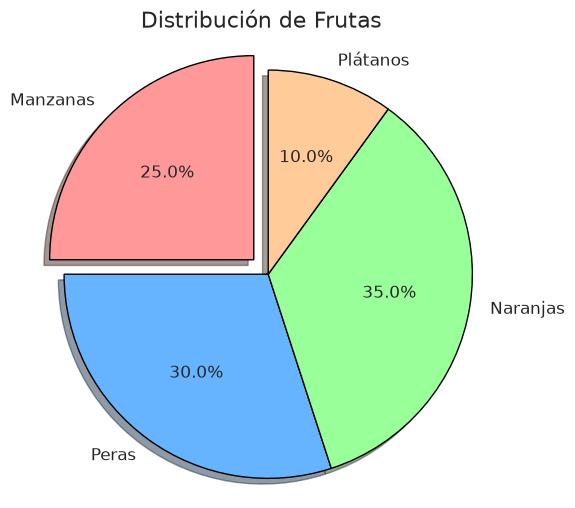

In [7]:
labels = ['Manzanas', 'Peras', 'Naranjas', 'Plátanos']
sizes = [25, 30, 35, 10]
colores = ['#ff9999','#66b3ff','#99ff99','#ffcc99']
explode = (0.1, 0, 0, 0)  # Destacar la primera porción

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(sizes, explode=explode, labels=labels, colors=colores, autopct='%1.1f%%',
       shadow=True, startangle=90, textprops={'fontsize': 12}, wedgeprops={'edgecolor': 'black'})
ax.set_title('Distribución de Frutas')
ax.axis('equal')  # Asegura que sea un círculo perfecto
plt.show()

### 7.3 Plotting Específico para Variables Numéricas (Distribuciones y Relaciones)

Para esto, Seaborn es el rey porque calcula estadísticas automáticamente.




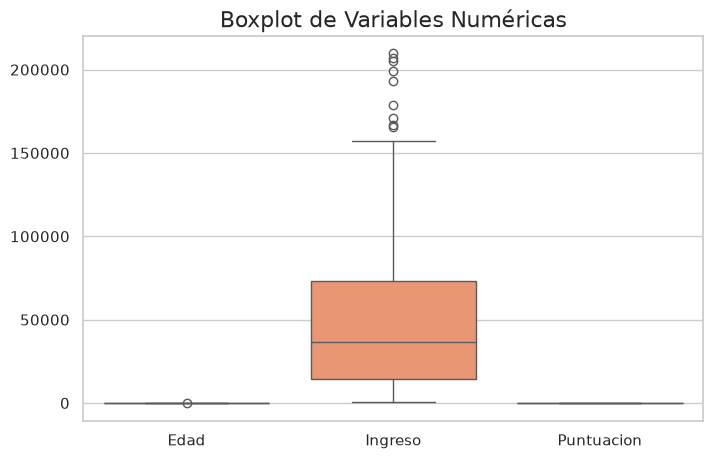

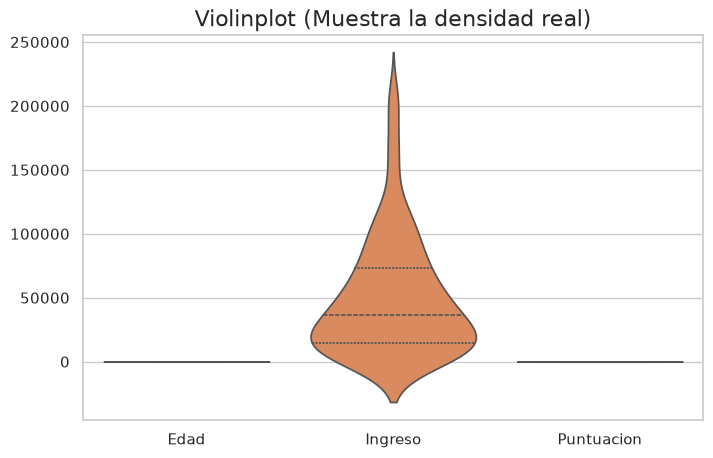

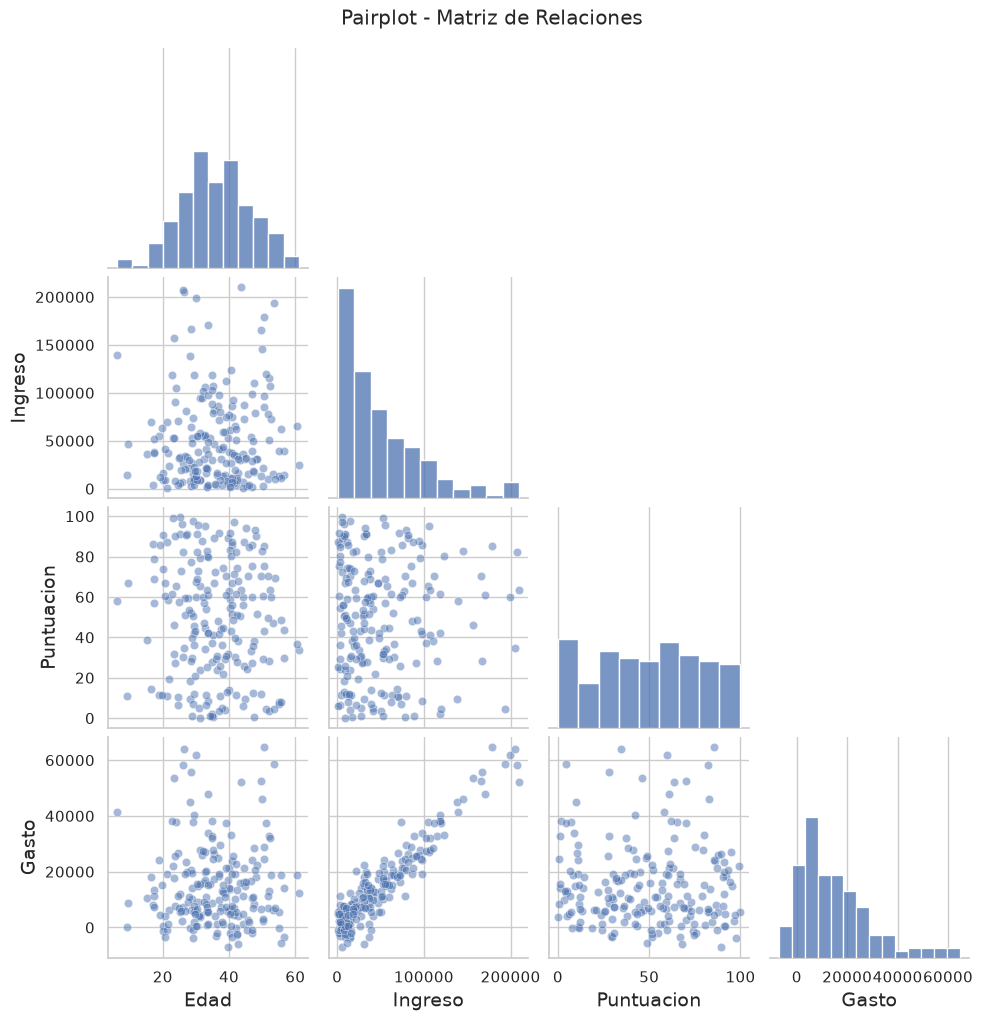

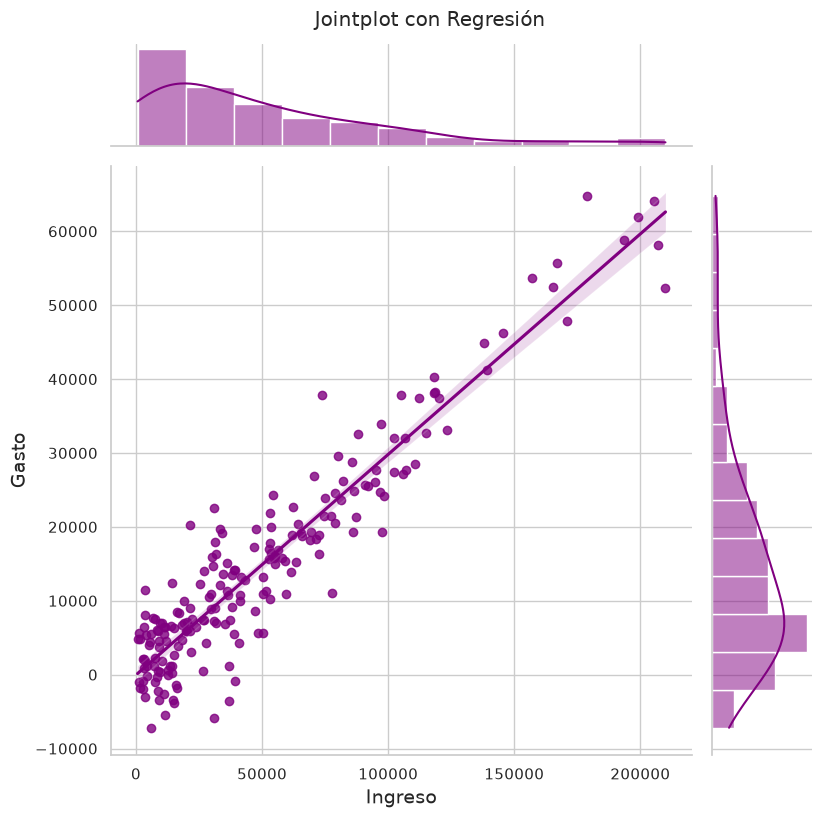

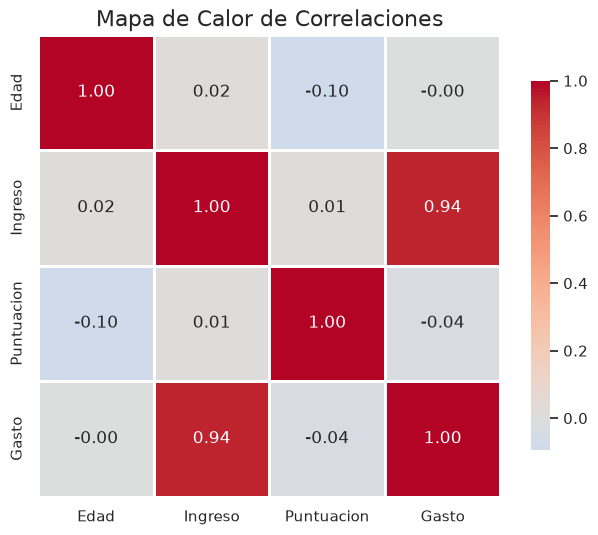

In [8]:
# Dataset de ejemplo
df_num = pd.DataFrame({
    'Edad': np.random.normal(35, 10, 200),
    'Ingreso': np.random.exponential(50000, 200),
    'Puntuacion': np.random.uniform(0, 100, 200)
})
# Añadimos algunas correlaciones
df_num['Gasto'] = df_num['Ingreso'] * 0.3 + np.random.normal(0, 5000, 200)

# --- 1. Boxplot (Muestra mediana, cuartiles y outliers) ---
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df_num[['Edad', 'Ingreso', 'Puntuacion']], palette='Set2', ax=ax)
ax.set_title('Boxplot de Variables Numéricas')
plt.show()

# --- 2. Violinplot (Boxplot + KDE) - MEJOR que boxplot solo ---
fig, ax = plt.subplots(figsize=(8, 5))
sns.violinplot(data=df_num[['Edad', 'Ingreso', 'Puntuacion']], palette='muted', inner='quartile', ax=ax)
ax.set_title('Violinplot (Muestra la densidad real)')
plt.show()

# --- 3. Pairplot (Matriz de dispersión) - PARA EXPLORAR TODO ---
# Diagonal: histogramas, fuera: scatter con regresión
sns.pairplot(df_num, diag_kind='hist', corner=True, plot_kws={'alpha': 0.5})
plt.suptitle('Pairplot - Matriz de Relaciones', y=1.02)
plt.show()

# --- 4. Jointplot (Scatter + Histogramas marginales) ---
g = sns.jointplot(data=df_num, x='Ingreso', y='Gasto', kind='reg',  # 'reg' añade recta de regresión
                  color='purple', height=8)
g.fig.suptitle('Jointplot con Regresión', y=1.02)
plt.show()

# --- 5. Heatmap de Correlaciones (para ver relaciones numéricas) ---
fig, ax = plt.subplots(figsize=(8, 6))
corr = df_num.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, 
            square=True, linewidths=1, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title('Mapa de Calor de Correlaciones')
plt.show()

### 7.4 Plotting Específico para Variables Categóricas


/tmp/ipykernel_19617/2103165058.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_cat, x='Ciudad', palette='viridis', ax=ax[0], order=df_cat['Ciudad'].value_counts().index)
/tmp/ipykernel_19617/2103165058.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_cat, y='Departamento', palette='plasma', ax=ax[1])  # Horizontal


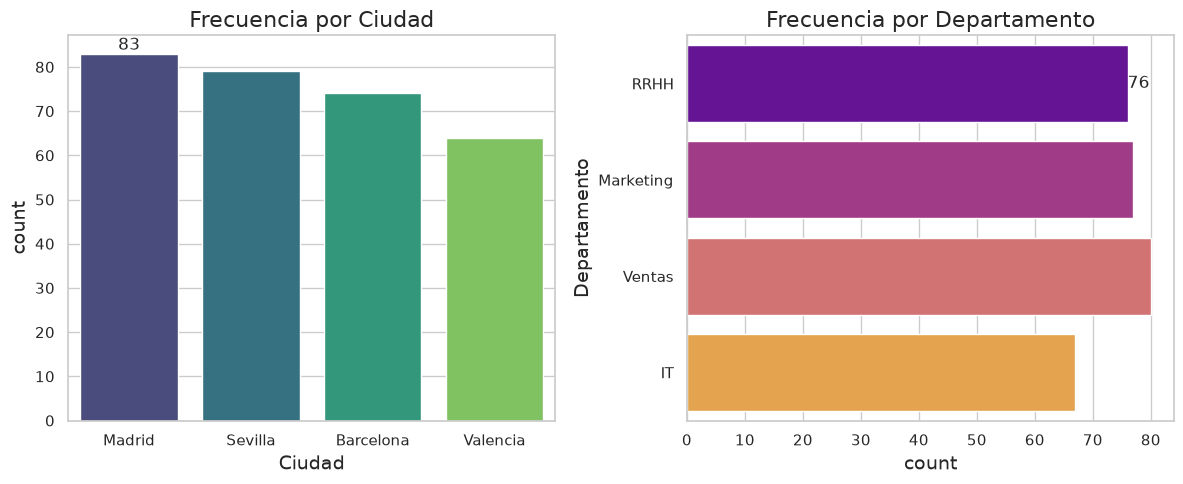

/tmp/ipykernel_19617/2103165058.py:25: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(data=df_cat, x='Ciudad', y='Salario', estimator=np.mean, ci='sd', palette='Set3', ax=ax)
/tmp/ipykernel_19617/2103165058.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_cat, x='Ciudad', y='Salario', estimator=np.mean, ci='sd', palette='Set3', ax=ax)


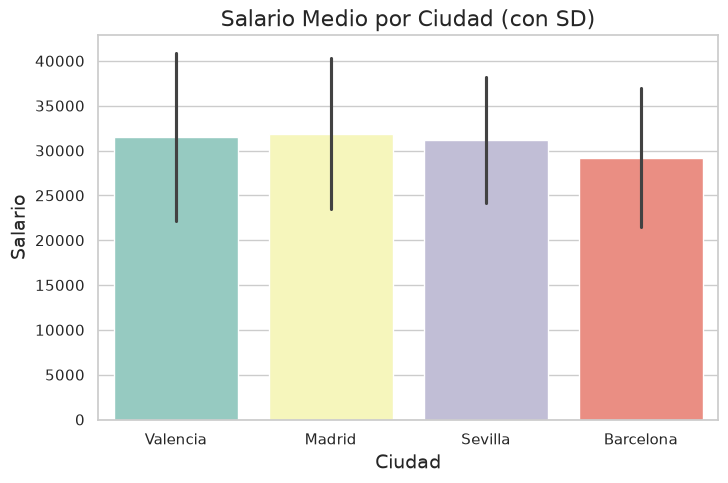

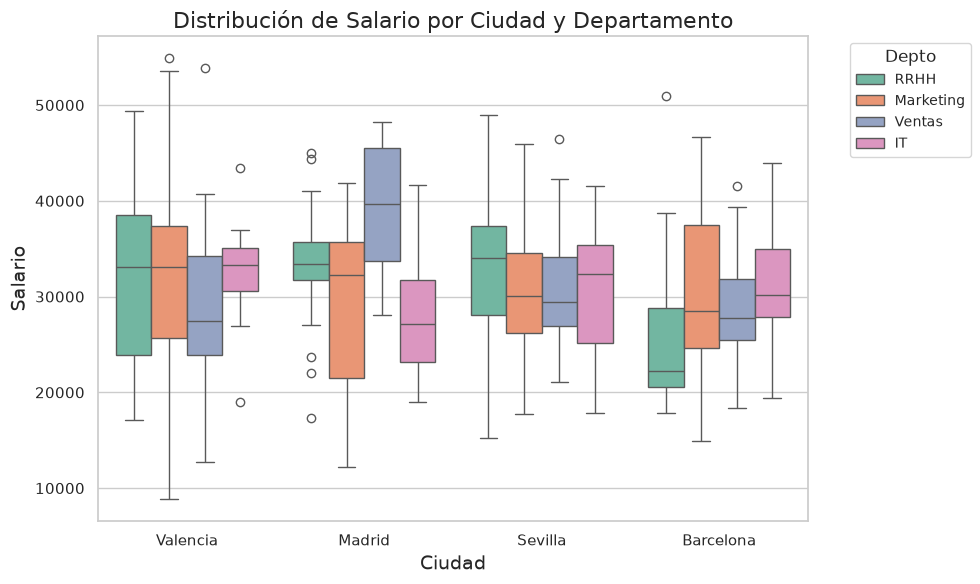

/tmp/ipykernel_19617/2103165058.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(data=df_cat, x='Departamento', y='Salario', col='Ciudad',  # Una columna por ciudad


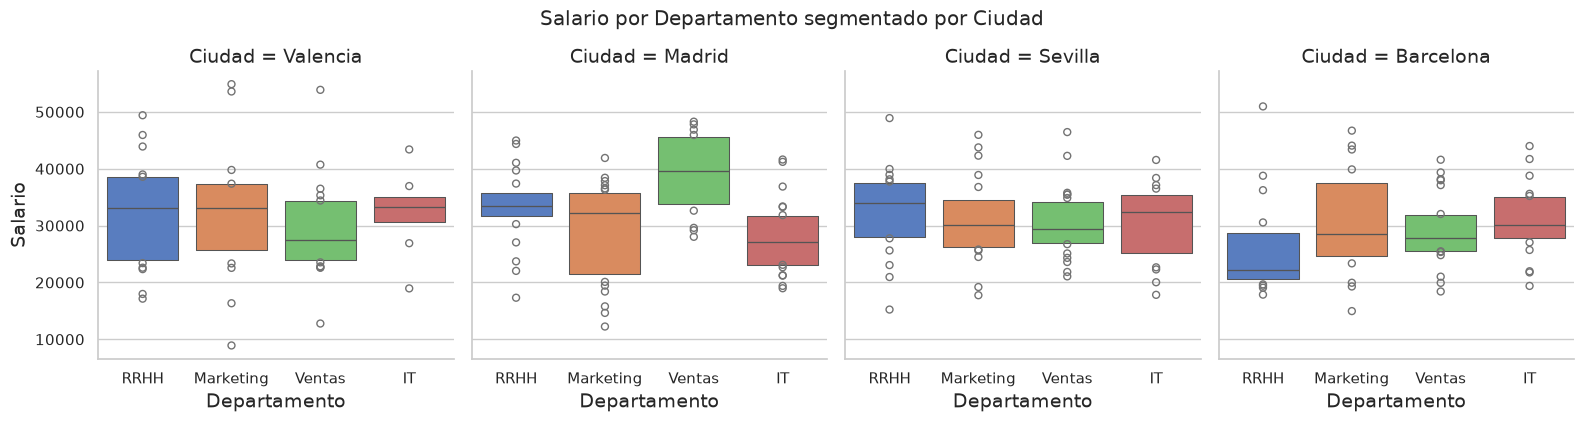

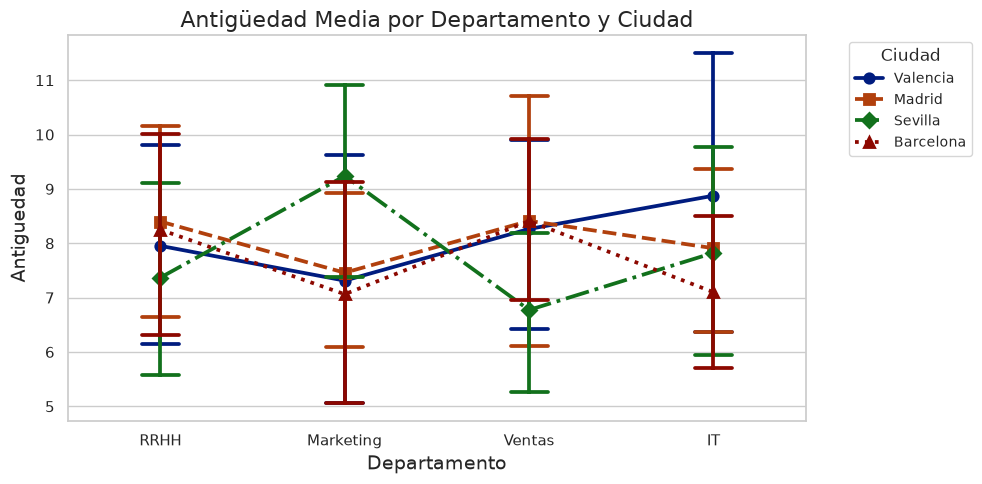

In [9]:
# Dataset con categóricas
df_cat = pd.DataFrame({
    'Ciudad': np.random.choice(['Madrid', 'Barcelona', 'Valencia', 'Sevilla'], size=300),
    'Departamento': np.random.choice(['Ventas', 'IT', 'RRHH', 'Marketing'], size=300),
    'Salario': np.random.normal(30000, 8000, 300),
    'Antiguedad': np.random.randint(1, 15, 300)
})
# Inyectar relación: Ventas gana más en Madrid
df_cat.loc[(df_cat['Ciudad'] == 'Madrid') & (df_cat['Departamento'] == 'Ventas'), 'Salario'] += 10000

# --- 1. Countplot (Frecuencia de categorías) ---
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sns.countplot(data=df_cat, x='Ciudad', palette='viridis', ax=ax[0], order=df_cat['Ciudad'].value_counts().index)
ax[0].set_title('Frecuencia por Ciudad')
ax[0].bar_label(ax[0].containers[0])  # Etiquetas encima

sns.countplot(data=df_cat, y='Departamento', palette='plasma', ax=ax[1])  # Horizontal
ax[1].set_title('Frecuencia por Departamento')
ax[1].bar_label(ax[1].containers[0])
plt.tight_layout()
plt.show()

# --- 2. Barplot (Agregación - Ej: Salario medio por categoría) ---
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=df_cat, x='Ciudad', y='Salario', estimator=np.mean, ci='sd', palette='Set3', ax=ax)
# ci='sd' muestra desviación estándar en lugar de IC al 95%
ax.set_title('Salario Medio por Ciudad (con SD)')
plt.show()

# --- 3. Boxplot por Categoría (Distribución condicionada) ---
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=df_cat, x='Ciudad', y='Salario', hue='Departamento', palette='Set2', ax=ax)
ax.set_title('Distribución de Salario por Ciudad y Departamento')
ax.legend(title='Depto', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# --- 4. Catplot (FacetGrid - Sublotes automáticos por categoría) ---
g = sns.catplot(data=df_cat, x='Departamento', y='Salario', col='Ciudad',  # Una columna por ciudad
                kind='boxen',  # 'boxen' es como boxplot pero para grandes volúmenes
                palette='muted', height=4, aspect=1)
g.fig.suptitle('Salario por Departamento segmentado por Ciudad', y=1.05)
plt.show()

# --- 5. Punto y Líneas para tendencias categóricas (Pointplot) ---
fig, ax = plt.subplots(figsize=(10, 5))
sns.pointplot(data=df_cat, x='Departamento', y='Antiguedad', hue='Ciudad', 
              markers=['o', 's', 'D', '^'], linestyles=['-', '--', '-.', ':'], 
              capsize=0.2, palette='dark', ax=ax)
ax.set_title('Antigüedad Media por Departamento y Ciudad')
ax.legend(title='Ciudad', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### 7.5 Múltiples Gráficos en una Figura (Subplots y GridSpec)


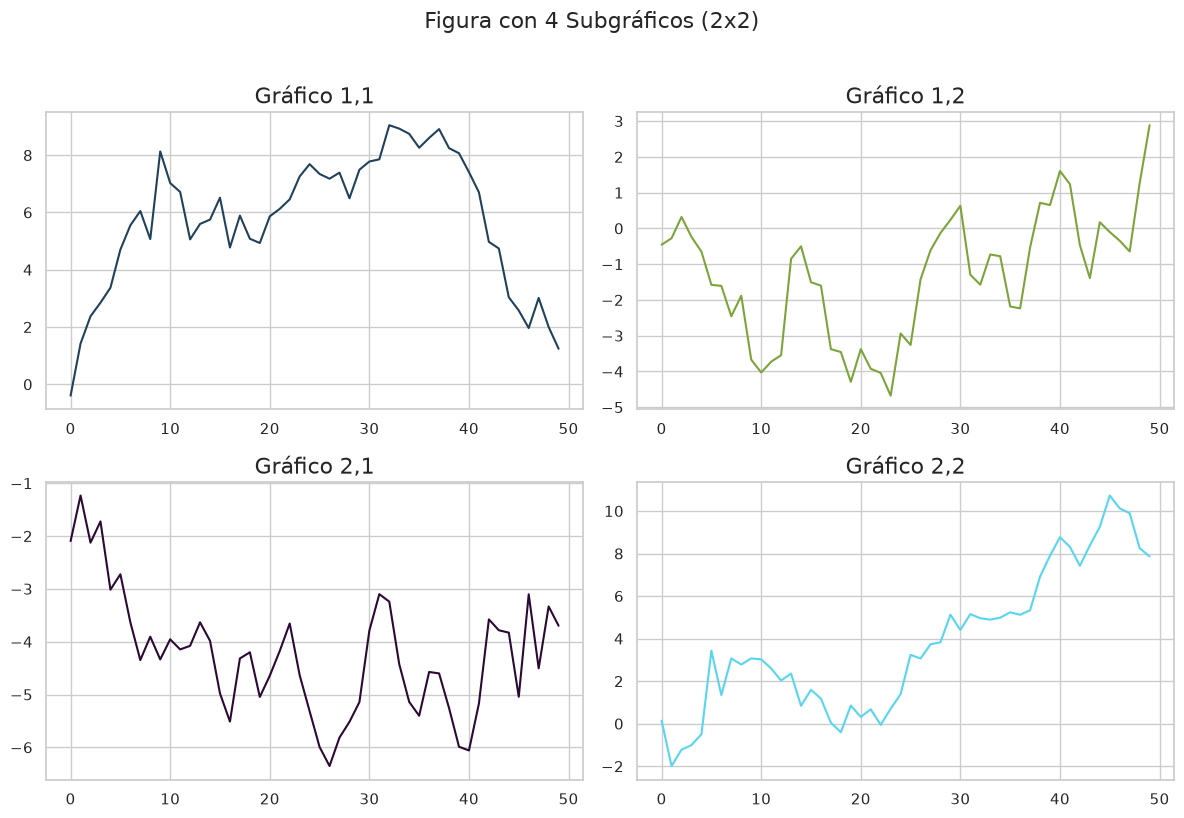

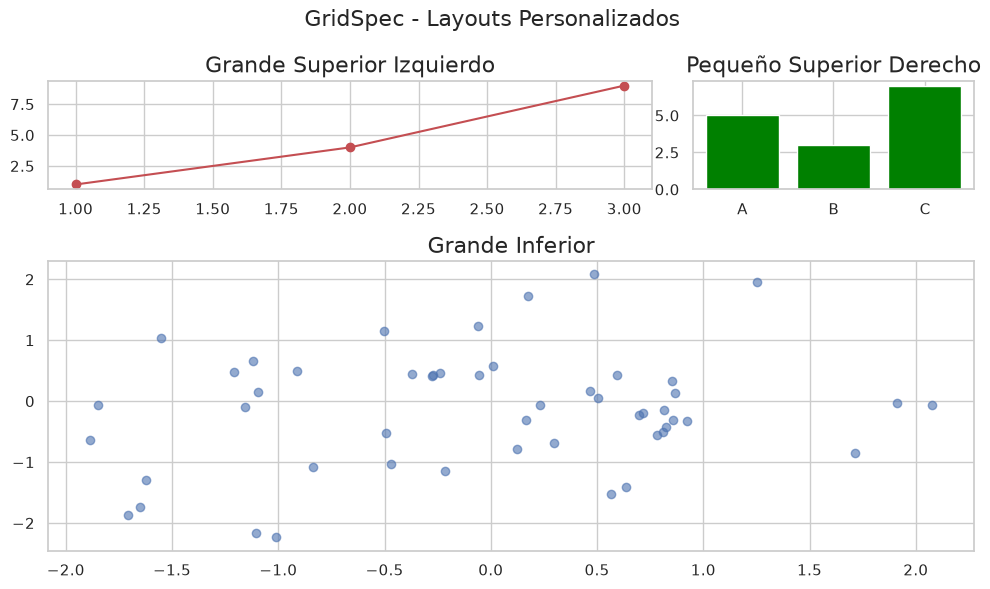

In [10]:
# --- Forma 1: subplots simples (filas, columnas) ---
fig, axes = plt.subplots(2, 2, figsize=(12, 8))  # 2x2
# axes es un array de 2x2: axes[0,0], axes[0,1], axes[1,0], axes[1,1]

# Ejemplo rápido rellenando cada uno
for i in range(2):
    for j in range(2):
        axes[i, j].plot(np.random.randn(50).cumsum(), color=np.random.rand(3,))
        axes[i, j].set_title(f'Gráfico {i+1},{j+1}')
        axes[i, j].grid(True)

plt.suptitle('Figura con 4 Subgráficos (2x2)', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

# --- Forma 2: GridSpec (Distribuciones complejas - tamaños diferentes) ---
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(10, 6))
gs = gridspec.GridSpec(3, 3, figure=fig)  # 3 filas, 3 columnas

# Ocupar espacio: [fila_inicio:fila_fin, col_inicio:col_fin]
ax1 = fig.add_subplot(gs[0, :2])   # Fila 0, columnas 0 y 1
ax2 = fig.add_subplot(gs[0, 2])    # Fila 0, columna 2
ax3 = fig.add_subplot(gs[1:, :])   # Filas 1 y 2, todas las columnas

ax1.plot([1,2,3], [1,4,9], 'ro-')
ax1.set_title('Grande Superior Izquierdo')

ax2.bar(['A','B','C'], [5,3,7], color='green')
ax2.set_title('Pequeño Superior Derecho')

ax3.scatter(np.random.randn(50), np.random.randn(50), alpha=0.6)
ax3.set_title('Grande Inferior')

plt.suptitle('GridSpec - Layouts Personalizados', fontsize=16)
plt.tight_layout()
plt.show()

### 7.6 Tuneo Finísimo: Etiquetas, Textos, Anotaciones y Ejes


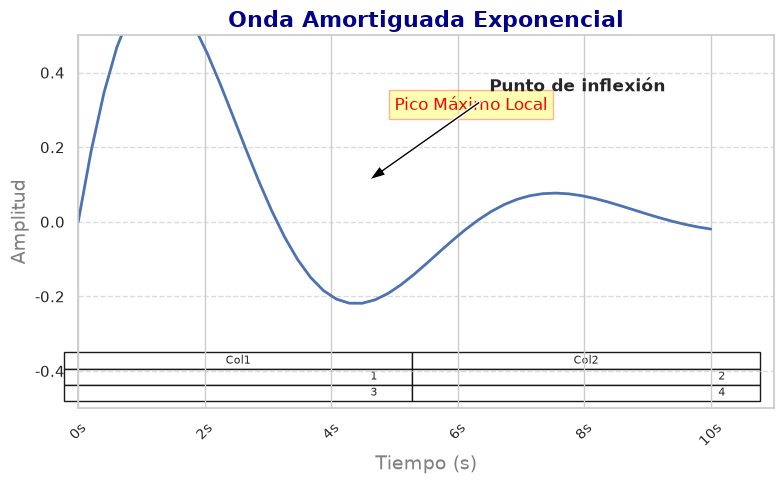

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))

x = np.linspace(0, 10, 50)
y = np.sin(x) * np.exp(-x/3)  # Onda amortiguada
ax.plot(x, y, 'b-', linewidth=2)

# 1. Títulos y Etiquetas (con tamaño y color)
ax.set_title('Onda Amortiguada Exponencial', fontsize=16, color='darkblue', fontweight='bold')
ax.set_xlabel('Tiempo (s)', fontsize=14, color='gray')
ax.set_ylabel('Amplitud', fontsize=14, color='gray')

# 2. Ajustar límites de los ejes (muy útil!)
ax.set_xlim([0, 11])
ax.set_ylim([-0.5, 0.5])

# 3. Personalizar Ticks (marcas) de los ejes
ax.set_xticks([0, 2, 4, 6, 8, 10])
ax.set_xticklabels(['0s', '2s', '4s', '6s', '8s', '10s'], rotation=45, fontsize=10) # Rotar si chocan
ax.set_yticks([-0.4, -0.2, 0.0, 0.2, 0.4])
ax.set_yticklabels(['-0.4', '-0.2', '0.0', '0.2', '0.4'])

# 4. Añadir texto libre en coordenadas (data o axes)
# Transformadas: ax.transData (coordenadas del gráfico), ax.transAxes (0 a 1 relativo)
ax.text(x=5, y=0.3, s='Pico Máximo Local', fontsize=12, color='red', 
        bbox=dict(facecolor='yellow', alpha=0.3, edgecolor='red'))

# 5. Añadir FLECHAS/ANOTACIONES (apuntando a un punto)
ax.annotate('Punto de inflexión', xy=(4.5, 0.1), xytext=(6.5, 0.35),
            arrowprops=dict(facecolor='black', shrink=0.05, width=2, headwidth=8),
            fontsize=12, fontweight='bold')

# 6. Añadir una cuadrícula específica solo para X o Y
ax.grid(axis='y', linestyle='--', alpha=0.7)  # Solo líneas horizontales

# 7. Añadir una tabla debajo del gráfico (sí, se puede)
tabla_datos = [[1, 2], [3, 4]]
tabla = ax.table(cellText=tabla_datos, loc='lower right', colLabels=['Col1', 'Col2'])
tabla.auto_set_font_size(False)
tabla.set_fontsize(8)

plt.tight_layout()
plt.show()

### 7.7 Colores y Paletas (El Arte de la Percepción)
Matplotlib tiene colores básicos y mapas de colores (colormaps). Seaborn añade paletas temáticas.

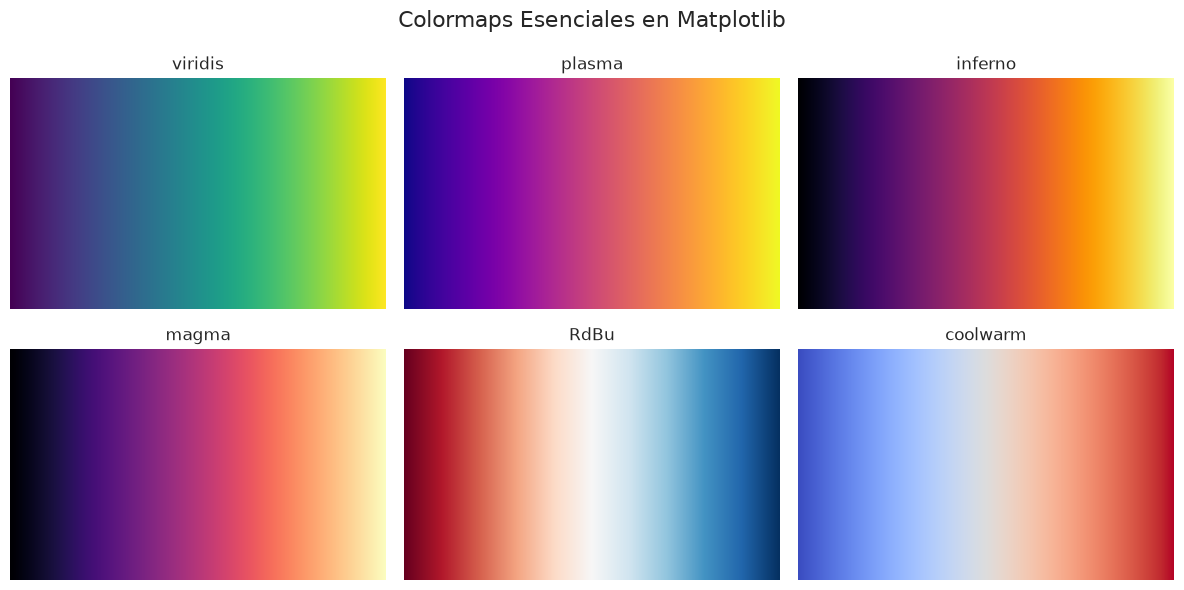

Paleta HUSL (8 colores): [(0.9677975592919913, 0.44127456009157356, 0.5358103155058701), (0.8087954113106306, 0.5634700050056693, 0.19502642696727285), (0.5920891529639701, 0.6418467016378244, 0.1935069134991043), (0.19783576093349015, 0.6955516966063037, 0.3995301037444499), (0.21044753832183283, 0.6773105080456748, 0.6433941168468681), (0.22335772267769388, 0.6565792317435265, 0.8171355503265633), (0.6423044349219739, 0.5497680051256467, 0.9582651433656727), (0.96038885399407, 0.3814317878772117, 0.8683117650835491)]


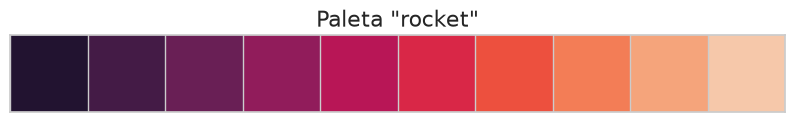

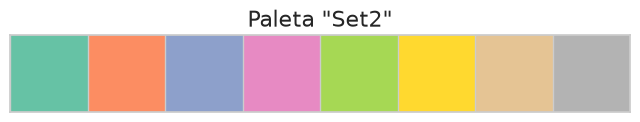

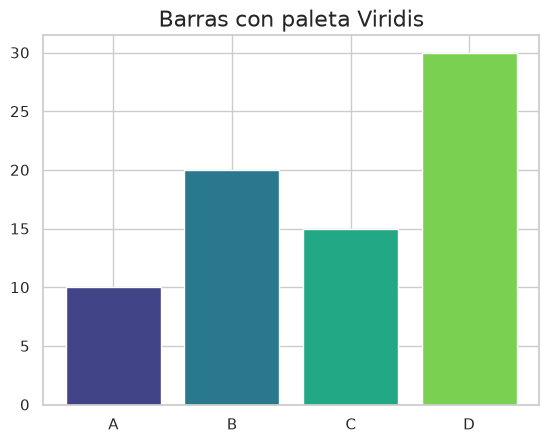

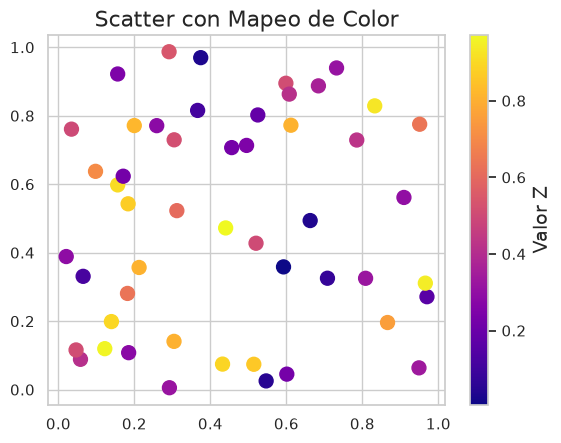

In [12]:
# --- COLORES BÁSICOS (Matplotlib) ---
# Formas válidas:
# 1. Nombre: 'red', 'blue', 'green', 'cyan', 'magenta', 'yellow', 'black', 'white'
# 2. Abreviatura: 'r', 'g', 'b', 'c', 'm', 'y', 'k', 'w'
# 3. Hex: '#FF5733'
# 4. RGB/RGBA: (0.2, 0.4, 0.6, 0.8)
# 5. Escala de grises: '0.75' (0=negro, 1=blanco)

# --- COLORMAPS (Para variables continuas como en heatmaps/scatters) ---
# Divergentes (buenos para datos con un punto medio neutro): 'RdBu', 'coolwarm', 'seismic'
# Secuenciales (de claro a oscuro): 'viridis', 'plasma', 'inferno', 'magma', 'cividis' (PERCEPTUALES Y UNIFORMES - USA ESTOS)
# Cualitativos (para categorías): 'tab10', 'tab20', 'Set1', 'Set2', 'Set3'

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
colormaps = ['viridis', 'plasma', 'inferno', 'magma', 'RdBu', 'coolwarm']

for ax, cmap in zip(axes.flat, colormaps):
    # Mostrar el colormap como una barra de colores
    gradient = np.linspace(0, 1, 256).reshape(1, -1)
    ax.imshow(gradient, aspect='auto', cmap=plt.get_cmap(cmap))
    ax.set_title(cmap, fontsize=12)
    ax.set_axis_off()
plt.suptitle('Colormaps Esenciales en Matplotlib', fontsize=16)
plt.tight_layout()
plt.show()

# --- PALETAS DE SEABORN (Para barras, boxplots, etc) ---
# 1. Paletas Cualitativas (para categorías sin orden): 'deep', 'muted', 'pastel', 'dark', 'bright', 'colorblind'
# 2. Paletas Secuenciales (para orden): 'Blues', 'Greens', 'Reds', 'Oranges' (o 'flare', 'crest')
# 3. Paletas Divergentes: 'Spectral', 'RdYlGn'

# Ejemplo de uso directo
paleta_cualitativa = sns.color_palette("husl", 8)  # 8 colores de la rueda HUSL
print(f"Paleta HUSL (8 colores): {paleta_cualitativa}")

# Visualizar cualquier paleta
sns.palplot(sns.color_palette("rocket", 10))  # Secuencial
plt.title('Paleta "rocket"')
plt.show()

sns.palplot(sns.color_palette("Set2", 8))  # Cualitativa
plt.title('Paleta "Set2"')
plt.show()

# --- CÓMO APLICAR COLORES EN GRÁFICOS ---

df_color = pd.DataFrame({'Cat': ['A','B','C','D'], 'Val': [10, 20, 15, 30]})

# 1. Usando una paleta de Seaborn directamente en matplotlib
fig, ax = plt.subplots()
colores = sns.color_palette("viridis", 4)  # 4 colores
ax.bar(df_color['Cat'], df_color['Val'], color=colores)
ax.set_title('Barras con paleta Viridis')
plt.show()

# 2. Mapear una columna numérica a un colormap (scatter)
np.random.seed(42)
df_scatter = pd.DataFrame({'x': np.random.rand(50), 'y': np.random.rand(50), 'z': np.random.rand(50)})
fig, ax = plt.subplots()
sc = ax.scatter(df_scatter['x'], df_scatter['y'], c=df_scatter['z'], cmap='plasma', s=100)
plt.colorbar(sc, label='Valor Z')
ax.set_title('Scatter con Mapeo de Color')
plt.show()

# 3. Cambiar la paleta global de Seaborn para todos los gráficos del notebook
sns.set_palette("husl")  # Ahora todos los gráficos usarán esta paleta por defecto.
# Para resetear: sns.set_palette("deep")

### 7.8 Estilos Globales y Personalización con rcParams
Para no repetir configuración en cada gráfico, se puede establecer un tema global.

In [13]:
# Ver todos los parámetros configurables
# print(plt.rcParams.keys())

# Configuración avanzada (poner al inicio del notebook)
plt.rcParams['figure.figsize'] = (10, 6)          # Tamaño por defecto de las figuras
plt.rcParams['figure.dpi'] = 100                  # Resolución
plt.rcParams['font.family'] = 'sans-serif'        # Fuente
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']  # Fuentes alternativas
plt.rcParams['axes.grid'] = True                  # Activar grid por defecto
plt.rcParams['grid.alpha'] = 0.3                  # Transparencia de la grid
plt.rcParams['lines.linewidth'] = 2               # Grosor de líneas por defecto
plt.rcParams['legend.frameon'] = True
plt.rcParams['legend.shadow'] = True

# Para volver a los valores por defecto: plt.rcParams.update(plt.rcParamsDefault)

### 7.9 Guardar Figuras (Alta Calidad para Publicaciones)


Figura guardada exitosamente.


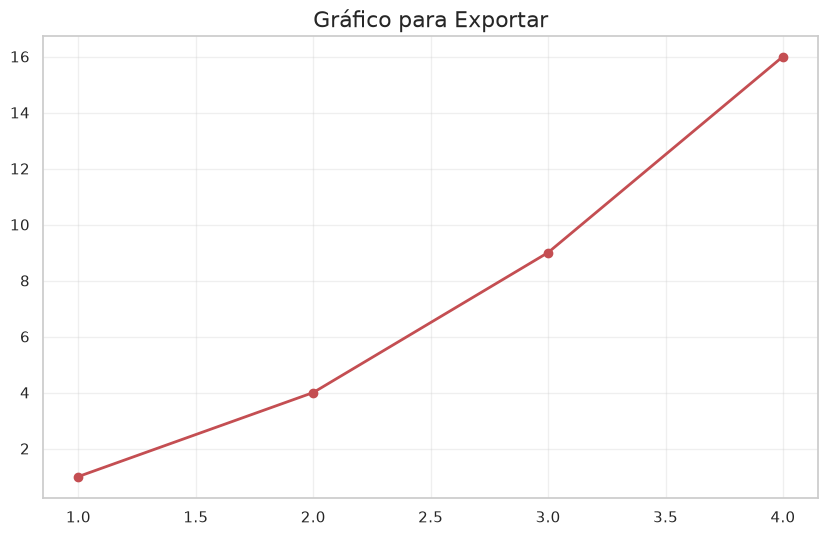

In [14]:
fig, ax = plt.subplots()
ax.plot([1,2,3,4], [1,4,9,16], 'ro-')
ax.set_title('Gráfico para Exportar')

# Guardar en alta resolución
fig.savefig('mi_grafico.png', dpi=300, bbox_inches='tight', transparent=False, facecolor='white')
# formatos: 'png', 'pdf', 'svg', 'eps'
# bbox_inches='tight' recorta los bordes blancos sobrantes

# Guardar con transparencia (útil para solapamientos)
fig.savefig('mi_grafico_transparente.png', dpi=300, bbox_inches='tight', transparent=True)

print("Figura guardada exitosamente.")

### 7.10 Bonus: Gráficos 3D 


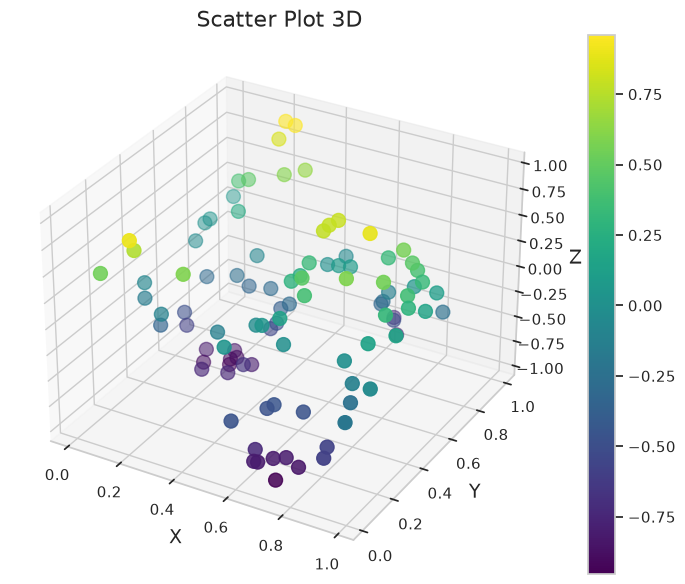

In [15]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

x = np.random.rand(100)
y = np.random.rand(100)
z = np.sin(x * 2 * np.pi) * np.cos(y * 2 * np.pi)

sc = ax.scatter(x, y, z, c=z, cmap='viridis', s=100)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Scatter Plot 3D')
plt.colorbar(sc)
plt.show()


## 7.11 Guía Rápida: ¿Qué gráfico usar para qué? (Toma de decisiones)

| **Propósito** | **Variables** | **Gráfico Recomendado** | **Comando Clave** |
| :--- | :--- | :--- | :--- |
| **Distribución** | 1 Numérica | Histograma / KDE / Boxplot / Violinplot | `sns.histplot`, `sns.boxplot`, `sns.violinplot` |
| **Distribución** | 2 Numéricas | Scatter plot / Hexbin | `plt.scatter`, `plt.hexbin` |
| **Distribución** | >2 Numéricas | Pairplot / Heatmap de correlación | `sns.pairplot`, `sns.heatmap` |
| **Comparación** | 1 Categórica + 1 Numérica | Barplot (medias) / Boxplot (distribución) | `sns.barplot`, `sns.boxplot` |
| **Comparación** | 2 Categóricas + 1 Numérica | Boxplot con `hue` / Catplot | `sns.boxplot(hue=...)`, `sns.catplot` |
| **Composición** | Categórica (proporciones) | Barras apiladas / Torta (solo si < 6 categorías) | `plt.bar(stacked=True)`, `plt.pie` |
| **Tendencia** | Numérica vs Numérica (orden) | Líneas (series temporales) / Scatter con regresión | `plt.plot`, `sns.regplot` |
| **Relación Jerárquica**| Múltiples categorías | Treemap (biblioteca externa) / Barras agrupadas | `sns.barplot` con `hue` |
| **Outliers** | Numérica | Boxplot / Violinplot | `sns.boxplot` |


### 7.12 Resumen de Buenas Prácticas en Visualización

1. **Contexto > Decoración:** Asegúrate de que el gráfico responde a una pregunta concreta.
2. **Percepción visual:** El ojo humano compara mejor áreas en posición horizontal (barras) que en ángulos (torta) o áreas (tortas 3D). **Evita las tortas 3D a toda costa.**
3. **Color:** Usa paletas perceptualmente uniformes (`viridis`, `plasma`) para datos secuenciales. Usa paletas divergentes (`RdBu`) para datos con un punto medio crítico (ej: correlaciones positivas/negativas).
4. **Texto:** Todas las etiquetas deben ser legibles (tamaño adecuado, sin rotaciones extremas si es posible). Añade unidades a los ejes (ej: "€", "km/h").
5. **Integridad:** El eje Y debe empezar en 0 para gráficos de barras (para no exagerar diferencias). En líneas/scatters está bien recortar si se muestra claramente.
6. **Rendimiento:** Para millones de puntos, usa `plot` con `alpha` bajo o `hexbin` en lugar de `scatter`.
